In [6]:
import pandas as pd

df = pd.read_csv("/netflix_titles_nov_2019.csv")

print(df.shape)         # rows and columns
print(df.head())        # first 5 rows
print(df.info())        # column types and non-null counts
print(df.isnull().sum())  # missing values per column

(5837, 12)
    show_id                                title                    director  \
0  81193313                            Chocolate                         NaN   
1  81197050  Guatemala: Heart of the Mayan World  Luis Ara, Ignacio Jaunsolo   
2  81213894                      The Zoya Factor             Abhishek Sharma   
3  81082007                            Atlantics                   Mati Diop   
4  80213643                      Chip and Potato                         NaN   

                                                cast  \
0  Ha Ji-won, Yoon Kye-sang, Jang Seung-jo, Kang ...   
1                                  Christian Morales   
2  Sonam Kapoor, Dulquer Salmaan, Sanjay Kapoor, ...   
3  Mama Sane, Amadou Mbow, Ibrahima Traore, Nicol...   
4  Abigail Oliver, Andrea Libman, Briana Buckmast...   

                    country         date_added  release_year rating  \
0               South Korea  November 30, 2019          2019  TV-14   
1                       NaN  

In [7]:
# 1. Missing values as a percentage of each column
print((df.isnull().sum() / len(df) * 100).round(1))

# 2. Duplicates: full-row duplicates, and repeated show_ids
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["show_id"].duplicated().sum())

# 3. Fill missing values
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna(df["rating"].mode()[0])

# 4. Convert date_added to a real date and pull out year and month
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="mixed")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# 5. Check the result
print(df.isnull().sum())
print(df.dtypes)

show_id          0.0
title            0.0
director        32.6
cast             9.5
country          7.3
date_added      11.0
release_year     0.0
rating           0.2
duration         0.0
listed_in        0.0
description      0.0
type             0.0
dtype: float64
Duplicate rows: 0
Duplicate IDs: 0
show_id           0
title             0
director          0
cast              0
country           0
date_added      642
release_year      0
rating            0
duration          0
listed_in         0
description       0
type              0
year_added      642
month_added     642
dtype: int64
show_id                  int64
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
type                    object
year_added             float64
mo

In [8]:
# 1. Make year and month proper integers (missing stays missing)
df["year_added"] = df["year_added"].astype("Int64")
df["month_added"] = df["month_added"].astype("Int64")

# 2. Split duration into two clean numeric columns
df["movie_minutes"] = (
    df.loc[df["type"] == "Movie", "duration"]
    .str.extract(r"(\d+)")[0]
    .astype(int)
)
df["tv_seasons"] = (
    df.loc[df["type"] == "TV Show", "duration"]
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

# 3. Check the new columns
print(df["movie_minutes"].describe())
print(df["tv_seasons"].value_counts().sort_index())

# 4. One genre per row (a separate table, so df stays unchanged)
genres = df[["show_id", "type", "listed_in"]].copy()
genres["genre"] = genres["listed_in"].str.split(", ")
genres = genres.explode("genre")

print(genres["genre"].value_counts().head(10))

count    3939.000000
mean       98.029195
std        27.719096
min         3.000000
25%        85.000000
50%        97.000000
75%       113.000000
max       312.000000
Name: movie_minutes, dtype: float64
tv_seasons
1.0     1259
2.0      298
3.0      157
4.0       60
5.0       46
6.0       21
7.0       21
8.0       16
9.0        7
10.0       3
11.0       3
12.0       2
13.0       2
14.0       1
15.0       2
Name: count, dtype: int64
genre
International Movies      1797
Dramas                    1488
Comedies                   992
International TV Shows     966
Documentaries              658
TV Dramas                  574
Action & Adventure         532
Independent Movies         516
TV Comedies                425
Crime TV Shows             355
Name: count, dtype: int64


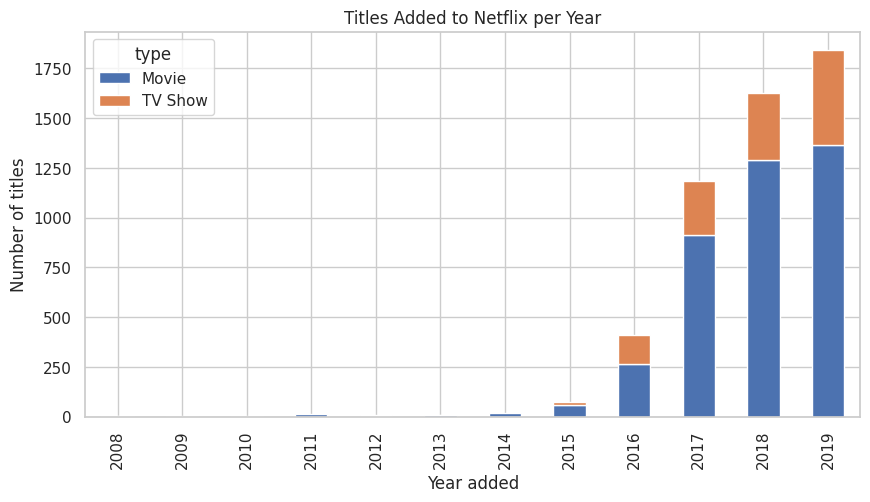

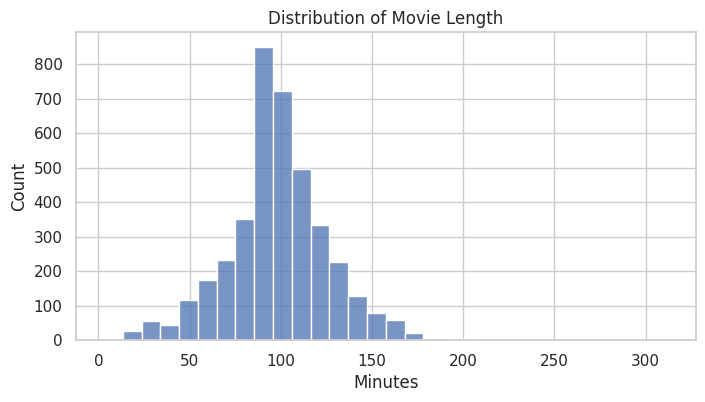

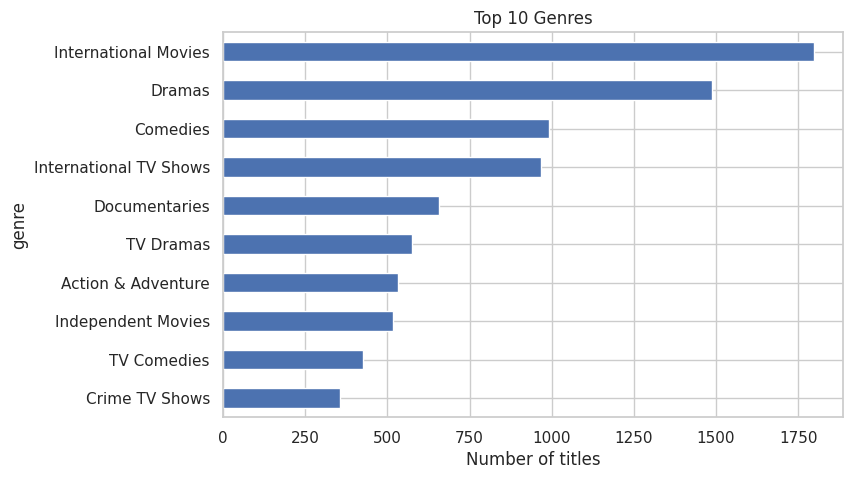

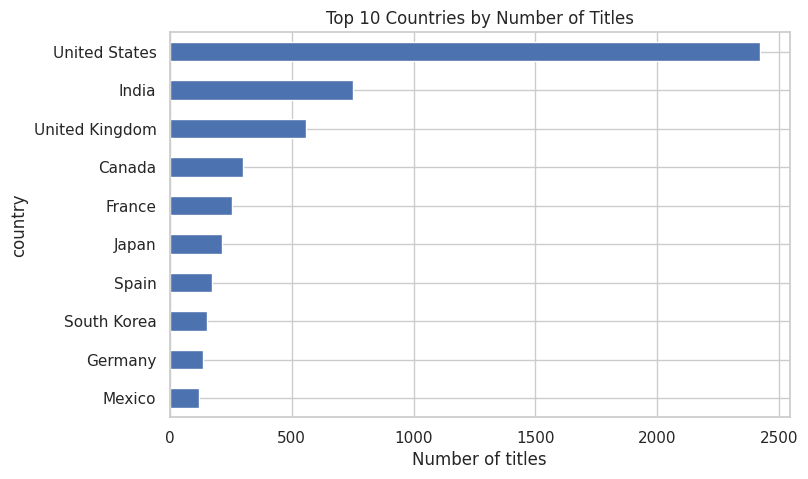

                                                  title  movie_minutes
306   The Road to El Camino: Behind the Scenes of El...           14.0
634    American Factory: A Conversation with the Obamas           10.0
1050                                              ANIMA           15.0
1183                     Cosmos Laundromat: First Cycle           12.0
1185                                             Silent            3.0
2451                  Calico Critters: A Town of Dreams           11.0
2937                                               Zion           12.0
3350                                      Pocoyo & Cars           19.0
4540                Buddy Thunderstruck: The Maybe Pile           14.0
4683                             Michael Lost and Found           19.0
4931                               The Battle of Midway           18.0
                           title  movie_minutes
2160  Black Mirror: Bandersnatch          312.0


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# Chart 1: titles added per year, split by type
yearly = df.groupby(["year_added", "type"]).size().unstack(fill_value=0)
yearly.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Titles Added to Netflix per Year")
plt.xlabel("Year added")
plt.ylabel("Number of titles")
plt.show()

# Chart 2: how long are the movies?
plt.figure(figsize=(8, 4))
sns.histplot(df["movie_minutes"].dropna(), bins=30)
plt.title("Distribution of Movie Length")
plt.xlabel("Minutes")
plt.show()

# Chart 3: top 10 genres
plt.figure(figsize=(8, 5))
genres["genre"].value_counts().head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Genres")
plt.xlabel("Number of titles")
plt.show()

# Chart 4: top 10 countries (each title can list several countries)
countries = df["country"].str.split(",").explode().str.strip()
countries = countries[(countries != "Unknown") & (countries != "")]
plt.figure(figsize=(8, 5))
countries.value_counts().head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Number of Titles")
plt.xlabel("Number of titles")
plt.show()

# Outlier check
print(df.loc[df["movie_minutes"] < 20, ["title", "movie_minutes"]])
print(df.loc[df["movie_minutes"] > 250, ["title", "movie_minutes"]])

In [10]:
# 1. Titles added per year (check the trend and the 2019 bar)
print(df["year_added"].value_counts().sort_index())

# 2. Movie vs TV Show share
print(df["type"].value_counts(normalize=True).mul(100).round(1))

# 3. Top countries as a percentage of all country mentions
print(countries.value_counts(normalize=True).mul(100).round(1).head(5))

# 4. Movie length: how many fall between 80 and 120 minutes?
share = df["movie_minutes"].between(80, 120).sum() / df["movie_minutes"].notna().sum() * 100
print(round(share, 1))

# 5. Your outlier check from before (paste what it showed)
print(df.loc[df["movie_minutes"] < 20, ["title", "movie_minutes"]])
print(df.loc[df["movie_minutes"] > 250, ["title", "movie_minutes"]])

year_added
2008       2
2009       2
2010       1
2011      13
2012       7
2013       9
2014      19
2015      74
2016     412
2017    1184
2018    1629
2019    1843
Name: count, dtype: Int64
type
Movie      67.5
TV Show    32.5
Name: proportion, dtype: float64
country
United States     36.1
India             11.2
United Kingdom     8.3
Canada             4.5
France             3.8
Name: proportion, dtype: float64
62.5
                                                  title  movie_minutes
306   The Road to El Camino: Behind the Scenes of El...           14.0
634    American Factory: A Conversation with the Obamas           10.0
1050                                              ANIMA           15.0
1183                     Cosmos Laundromat: First Cycle           12.0
1185                                             Silent            3.0
2451                  Calico Critters: A Town of Dreams           11.0
2937                                               Zion           12.0
3350    